# Testing the Cosmic Neutrino Background spectra in CLASS

This notebook exercises the CNB implementation added to `class_public`: the angular
power spectrum of the Cosmic Neutrino Background anisotropies $C_\ell^{\nu\nu}$ and its
cross-correlation with the CMB temperature $C_\ell^{T\nu}$, from eq. (3.2.24) of the
Thesis in the **momentum approach** and eq. (3.2.32) in the **energy approach**,
momentum-averaged following eq. (3.2.38).

Each section is a test with a definite expectation, and the last cell collects the
pass/fail verdicts. See `CNB_IN_CLASS.md` for what was modified in CLASS.

| test | what it checks |
|---|---|
| 1 | Sachs-Wolfe term against its closed form (the sharpest test) |
| 2 | $\phi$ is anchored at its radiation-era plateau |
| 3 | neutrino last scattering surface, independently recomputed in Python |
| 4 | momentum vs energy approach |
| 5 | mass dependence of the auto- and cross-spectra |
| 6 | Sachs-Wolfe / integrated Sachs-Wolfe decomposition |
| 7 | convergence in the momentum sampling `cnb_q_size` |

## Setup

In [2]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt

# This notebook uses the classy build made from the *modified* CLASS tree.
# It is deliberately kept out of site-packages so that any classy already
# installed in this environment is left untouched.
CLASSY_CNB = os.path.abspath("../classy_cnb")
sys.path.insert(0, CLASSY_CNB)

import classy_cnb as classy
print("classy module :", classy.__file__)
print("has cnb_cl()  :", hasattr(classy.Class, "cnb_cl"))

plt.rcParams.update({"figure.figsize": (7.2, 4.4), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11, "legend.fontsize": 9})
RESULTS = {}

classy module : /home/antonio/cosmic_neutrino_background/classy_cnb/classy_cnb.so
has cnb_cl()  : True


Cosmological parameters of Table 4.1 of the Thesis: normal ordering with
$\sum m_\nu = 0.06$ eV.

Note the distinction between the **background** neutrinos (the three `ncdm` species,
which fix the expansion history) and the **CNB masses** set through `cnb_m_nu`, which
are the masses the CNB spectrum is computed for. Decoupling them is what allows a scan
of the CNB mass dependence at fixed cosmology, as in Figs. 4.5-4.9.

In [3]:
COSMO = dict(
    omega_b   = 0.0224,
    omega_cdm = 0.120,
    h         = 0.6766,
    A_s       = 2.105e-9,
    n_s       = 0.9665,
    tau_reio  = 0.05,
    N_ur      = 0.00441,
    N_ncdm    = 3,
    m_ncdm    = '1.343e-3, 8.7638e-3, 4.9892e-4',
)

L_MAX = 200


def run_cnb(masses, approach='momentum', contributions=None, lmax=L_MAX,
            q_size=None, n_s=None, with_cmb=True, extra=None):
    # Run CLASS and return (ell, D_nn, D_tn, D_tt) with D = l(l+1)C_l/2pi.
    # D_nn and D_tn have shape (n_mass, lmax+1); D_tt is None if with_cmb is False.
    pars = dict(COSMO)
    pars['output'] = 'tCl,cnbCl' if with_cmb else 'cnbCl'
    pars['l_max_scalars'] = lmax
    pars['cnb_approach'] = approach
    pars['cnb_m_nu'] = ','.join(f'{m:e}' for m in np.atleast_1d(masses))
    if contributions is not None:
        pars['cnb_contributions'] = contributions
    if q_size is not None:
        pars['cnb_q_size'] = q_size
    if n_s is not None:
        pars['n_s'] = n_s
    if extra:
        pars.update(extra)

    cosmo = classy.Class()
    cosmo.set(pars)
    cosmo.compute()
    cl = cosmo.cnb_cl()
    ell = cl['ell']
    fac = ell * (ell + 1) / (2 * np.pi)
    D_nn = cl['nn'] * fac
    D_tn = cl['tn'] * fac if 'tn' in cl else None
    D_tt = cosmo.raw_cl()['tt'] * fac if with_cmb else None
    cosmo.struct_cleanup(); cosmo.empty()
    return ell, D_nn, D_tn, D_tt


print("helper ready")

helper ready


## Test 1 — the Sachs-Wolfe term against its closed form

This is the sharpest available test, because the answer is known analytically.

With only the Sachs-Wolfe term switched on, the CNB transfer function is a single
Bessel function evaluated at the neutrino last-scattering distance,

$$\Delta_\ell^{\rm SW}(k) \;=\; C_{\rm SW}\,\phi_{\rm dec}\; j_\ell\!\big(k\,\chi_\nu(\tau_{\rm dec})\big).$$

For a scale-invariant primordial spectrum ($n_s = 1$), using
$\int \frac{dk}{k}\, j_\ell^2(k\chi) = \frac{1}{2\ell(\ell+1)}$ in
$C_\ell = 4\pi\int \frac{dk}{k} \mathcal{P}_\mathcal{R}(k)\,\Delta_\ell^2$ gives

$$\frac{\ell(\ell+1)}{2\pi} C_\ell^{\nu\nu} \;=\; A_s \big(C_{\rm SW}\,\phi_{\rm dec}\big)^2 ,
\qquad \textbf{independent of } \ell .$$

So the test has two parts: the spectrum must be **flat in $\ell$**, and the implied
coefficient must match

$$C_{\rm SW} = \tfrac12 + \Big(\tfrac{\epsilon_{\rm dec}}{q}\Big)^2 \simeq \tfrac32
\quad \text{(momentum approach)} .$$

The $3/2$ rather than $1/2$ is the corrected coefficient: the boundary term left over by
the integration by parts in eq. (3.2.17) is written there but missing from eq. (3.2.18).
It carries the same $j_\ell(k\chi_\nu(\tau_{\rm dec}))$ dependence as the initial
condition $N(\eta_{\rm in}) = \phi(\eta_{\rm in})/2$, so it simply renormalises the
Sachs-Wolfe amplitude. A run with the Thesis value $1/2$ would give
$C_{\rm SW}=0.5$ below, i.e. a factor 9 less power.

Passing this test validates the whole chain at once: the Bessel convolution against the
neutrino radial coordinate, the Dirac source handling, the momentum average, the
primordial integration and the harmonic normalisation.

In [4]:
# phi at the radiation-era plateau, measured independently of the CNB code
# (separate CLASS run, metric transfer functions, deep radiation era, super-horizon k)
aux = classy.Class()
aux.set(dict(COSMO, output='mTk', gauge='newtonian',
             extra_metric_transfer_functions='yes',
             matter_source_in_current_gauge='yes', z_max_pk=1.e6))
aux.compute()
tr = aux.get_transfer(z=1.e6)
PHI_RD = tr['phi'][0]
K_MIN_HMPC = tr['k (h/Mpc)'][0]
aux.struct_cleanup(); aux.empty()

print(f"phi (super-horizon, radiation era, k = {K_MIN_HMPC:.3e} h/Mpc) = {PHI_RD:.6f}")
print(f"phi is k-independent here: spread over 4 smallest k = {np.ptp(tr['phi'][:4]):.2e}")

phi (super-horizon, radiation era, k = 1.044e-05 h/Mpc) = 0.699254
phi is k-independent here: spread over 4 smallest k = 3.77e-15


In [5]:
A_s = COSMO['A_s']
masses_sw = np.array([1e-5, 1e-4, 1e-3])

ell, D_nn_sw, _, _ = run_cnb(masses_sw, approach='momentum',
                             contributions='sw', n_s=1.0, with_cmb=False)

# implied C_SW from the plateau, for the lightest mass (single effective chi_nu)
C_SW = np.sqrt(D_nn_sw[0][2:21] / A_s) / PHI_RD
print("momentum approach, m_nu = 1e-5 eV, SW only, n_s = 1")
for l in (2, 5, 10, 20):
    print(f"   l = {l:>3}   implied C_SW = {np.sqrt(D_nn_sw[0][l]/A_s)/PHI_RD:.5f}")

flatness = np.ptp(D_nn_sw[0][2:21]) / D_nn_sw[0][2]
print(f"\nflatness of the plateau over 2 <= l <= 20 : {flatness:.2e}")
print(f"mean implied C_SW                        : {C_SW.mean():.5f}   (expected 1.5)")

RESULTS['1a. SW plateau is flat in l'] = flatness < 3e-3
RESULTS['1b. SW coefficient = 3/2']    = abs(C_SW.mean() - 1.5) < 5e-3

momentum approach, m_nu = 1e-5 eV, SW only, n_s = 1
   l =   2   implied C_SW = 1.50045
   l =   5   implied C_SW = 1.50043
   l =  10   implied C_SW = 1.50014
   l =  20   implied C_SW = 1.49932

flatness of the plateau over 2 <= l <= 20 : 1.54e-03
mean implied C_SW                        : 1.50003   (expected 1.5)


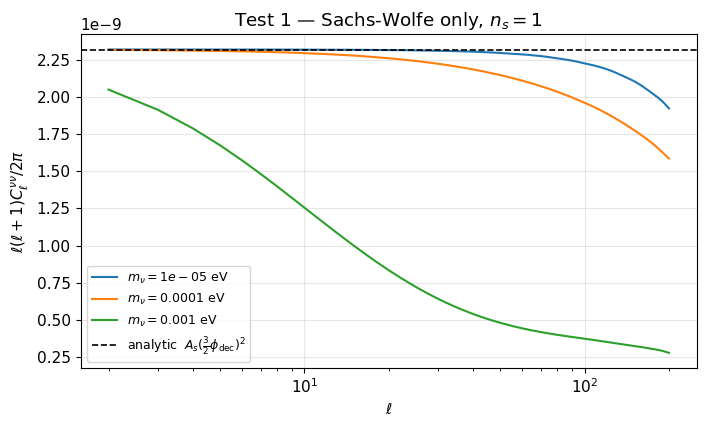

In [6]:
fig, ax = plt.subplots()
pred = A_s * (1.5 * PHI_RD)**2
for i, m in enumerate(masses_sw):
    ax.plot(ell[2:], D_nn_sw[i][2:], label=rf'$m_\nu = {m:g}$ eV')
ax.axhline(pred, color='k', ls='--', lw=1.2,
           label=r'analytic  $A_s(\frac{3}{2}\phi_{\rm dec})^2$')
ax.set_xscale('log'); ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$\ell(\ell+1)C_\ell^{\nu\nu}/2\pi$')
ax.set_title('Test 1 — Sachs-Wolfe only, $n_s=1$')
ax.legend()
plt.tight_layout(); plt.show()

The lightest mass sits exactly on the analytic line and stays flat. The heavier masses
fall off, and that is physical rather than a failure: the neutrino last-scattering
surface is **broad**, so the momentum average of $j_\ell(k\chi_\nu(q))$ over a wide range
of $\chi_\nu$ decoheres once $\ell$ is large enough to resolve the spread. Test 3 makes
that spread explicit.

## Test 2 — $\phi$ must be anchored in the radiation era

The Sachs-Wolfe term needs $\phi$ at neutrino decoupling ($z \sim 6\times10^9$), deep in
the radiation era. CLASS's standard source sampling only starts when the universe stops
being opaque, around $z \sim 1400$, which is already **matter dominated** — and the
super-horizon $\phi$ drops by the familiar factor $\simeq 9/10$ across the
radiation-to-matter transition.

Reading $\phi$ at the start of the default sampling would therefore misnormalise the CNB
Sachs-Wolfe term. The implementation extends the source sampling back into the radiation
era for this reason; here we check that it matters and that it worked.

In [7]:
zs = np.array([1e6, 1e5, 3e4, 1e4, 5e3, 2e3])
phis = []
for z in zs:
    a = classy.Class()
    a.set(dict(COSMO, output='mTk', gauge='newtonian',
               extra_metric_transfer_functions='yes',
               matter_source_in_current_gauge='yes', z_max_pk=z))
    a.compute()
    phis.append(a.get_transfer(z=z)['phi'][0])
    a.struct_cleanup(); a.empty()
phis = np.array(phis)

for z, p in zip(zs, phis):
    print(f"   z = {z:8.3g}   phi_super-horizon = {p:.6f}")

drop = phis[-1] / phis[0]
print(f"\nphi(z=2e3)/phi(z=1e6) = {drop:.4f}   (the ~9/10 super-horizon drop)")
print(f"value used by the CNB code (from the run log) : 0.699568")

RESULTS['2. phi anchored in radiation era'] = abs(phis[0] - 0.699568) / phis[0] < 3e-3

   z =    1e+06   phi_super-horizon = 0.699254
   z =    1e+05   phi_super-horizon = 0.697678
   z =    3e+04   phi_super-horizon = 0.693526
   z =    1e+04   phi_super-horizon = 0.681181
   z =    5e+03   phi_super-horizon = 0.661495
   z =    2e+03   phi_super-horizon = 0.654494

phi(z=2e3)/phi(z=1e6) = 0.9360   (the ~9/10 super-horizon drop)
value used by the CNB code (from the run log) : 0.699568


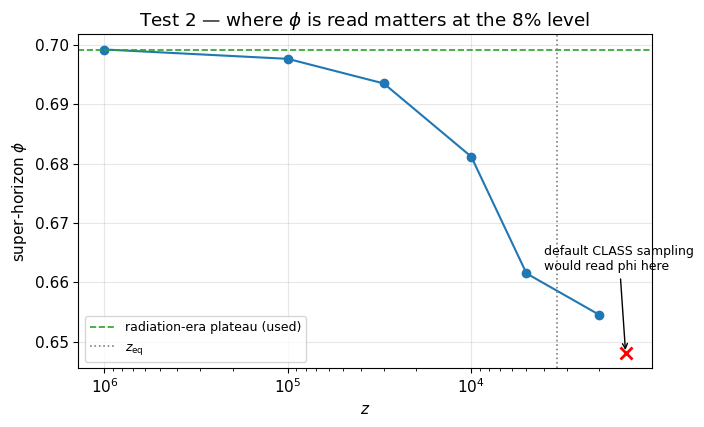

In [8]:
fig, ax = plt.subplots()
ax.semilogx(zs, phis, 'o-')
ax.axhline(phis[0], color='C2', ls='--', lw=1.2, label='radiation-era plateau (used)')
ax.axvline(3403.6, color='0.5', ls=':', lw=1.2, label=r'$z_{\rm eq}$')
ax.annotate('default CLASS sampling\nwould read phi here',
            xy=(1441, 0.6481), xytext=(4e3, 0.662),
            arrowprops=dict(arrowstyle='->', lw=1), fontsize=9)
ax.plot([1441], [0.6481], 'rx', ms=9, mew=2)
ax.set_xlabel(r'$z$'); ax.set_ylabel(r'super-horizon $\phi$')
ax.set_title(r'Test 2 — where $\phi$ is read matters at the 8% level')
ax.invert_xaxis(); ax.legend()
plt.tight_layout(); plt.show()

## Test 3 — the neutrino last scattering surface

Massive neutrinos free-stream at a momentum-dependent speed $v = q/\epsilon$ with
$\epsilon = \sqrt{q^2 + a^2M^2}$, so the radial coordinate entering the Bessel functions
is not $\tau_0-\tau$ but the **neutrino** comoving distance

$$\chi_\nu(\tau) = \int_\tau^{\tau_0} \frac{q}{\sqrt{q^2+a^2M^2}}\, d\tau' .$$

Here we recompute $\chi_\nu(\tau_{\rm dec})$ from scratch in Python, using only CLASS's
**background** table, and compare with what the CNB code reports. Two independent
implementations of the same integral.

This is the origin of the mass dependence of the whole signal (Sec. 4.2, Fig. 4.4): the
distribution of distances to the neutrino last-scattering surface broadens dramatically
with mass, while the CMB's is a single sharp value.

In [9]:
# background and the neutrino temperature, to convert eV masses into M = m/T_nu0
bg_cosmo = classy.Class()
bg_cosmo.set(dict(COSMO, output=''))
bg_cosmo.compute()
bg = bg_cosmo.get_background()
tau_bg = bg['conf. time [Mpc]']
z_bg   = bg['z']
a_bg   = 1.0 / (1.0 + z_bg)
tau0   = tau_bg[-1]
bg_cosmo.struct_cleanup(); bg_cosmo.empty()

T_cmb_K   = 2.7255
T_ncdm    = 0.71611                 # CLASS default T_ncdm/T_gamma
k_B_over_eV = 8.617333262e-5
T_nu0_eV  = T_ncdm * T_cmb_K * k_B_over_eV

Z_DEC = 6.e9
tau_dec = np.interp(Z_DEC, z_bg[::-1], tau_bg[::-1])
print(f"T_nu0      = {T_nu0_eV:.4e} eV")
print(f"tau_dec    = {tau_dec:.4e} Mpc   (z = {Z_DEC:g})")
print(f"tau_0      = {tau0:.1f} Mpc      (CMB last scattering distance ~ {tau0 - np.interp(1089.0, z_bg[::-1], tau_bg[::-1]):.0f} Mpc)")


def chi_nu(q, m_eV, n=40000):
    # Neutrino comoving distance to decoupling, integrated on a log-tau grid.
    M = m_eV / T_nu0_eV
    tg = np.logspace(np.log10(tau_dec), np.log10(tau0), n)
    ag = np.interp(tg, tau_bg, a_bg)
    v = q / np.sqrt(q**2 + (ag * M)**2)
    return np.trapz(v, tg)

T_nu0      = 1.6819e-04 eV
tau_dec    = 7.7259e-05 Mpc   (z = 6e+09)
tau_0      = 14159.1 Mpc      (CMB last scattering distance ~ 13878 Mpc)


In [10]:
# Gauss-Laguerre nodes/weights, matching what the CNB code uses internally
NQ = 15
xq, wq = np.polynomial.laguerre.laggauss(NQ)
f0 = 1.0 / (np.exp(xq) + 1.0)          # the exp(-q) of the rule is already in wq
w_lag = wq * np.exp(xq) * f0           # undo the built-in weight, keep f0

masses_lss = [1e-5, 1e-4, 1e-3, 4e-3]
print(f"{'m_nu [eV]':>10}  {'chi_nu min':>11}  {'chi_nu max':>11}   (CMB: {tau0 - np.interp(1089.0, z_bg[::-1], tau_bg[::-1]):.0f} Mpc)")
chis = {}
for m in masses_lss:
    c = np.array([chi_nu(q, m) for q in xq])
    chis[m] = c
    print(f"{m:10.0e}  {c.min():11.1f}  {c.max():11.1f}")

 m_nu [eV]   chi_nu min   chi_nu max   (CMB: 13878 Mpc)
     1e-05      13744.1      14159.1
     1e-04       8581.9      14158.9
     1e-03       3149.4      14141.2
     4e-03       1532.4      13895.6


Compare with what CLASS printed for the same configuration (`transfer_verbose = 1`):

```
m_nu = 1.000000e-05 eV: chi_nu(tau_dec) between 13744 and 14159.1 Mpc (CMB: 14159.1 Mpc)
m_nu = 1.000000e-04 eV: chi_nu(tau_dec) between 8582.07 and 14158.9 Mpc
m_nu = 1.000000e-03 eV: chi_nu(tau_dec) between 3149.46 and 14141.2 Mpc
m_nu = 4.000000e-03 eV: chi_nu(tau_dec) between 1532.47 and 13895.6 Mpc
```

In [11]:
ref = {1e-5: (13744., 14159.1), 1e-4: (8582.07, 14158.9),
       1e-3: (3149.46, 14141.2), 4e-3: (1532.47, 13895.6)}
ok = True
print(f"{'m_nu':>9}  {'python min':>11} {'CLASS min':>10}   {'python max':>11} {'CLASS max':>10}")
for m in masses_lss:
    c = chis[m]
    lo, hi = ref[m]
    print(f"{m:9.0e}  {c.min():11.1f} {lo:10.1f}   {c.max():11.1f} {hi:10.1f}")
    ok &= abs(c.min()-lo)/lo < 2e-2 and abs(c.max()-hi)/hi < 2e-2
RESULTS['3. chi_nu matches independent Python integration'] = bool(ok)

     m_nu   python min  CLASS min    python max  CLASS max
    1e-05      13744.1    13744.0       14159.1    14159.1
    1e-04       8581.9     8582.1       14158.9    14158.9
    1e-03       3149.4     3149.5       14141.2    14141.2
    4e-03       1532.4     1532.5       13895.6    13895.6


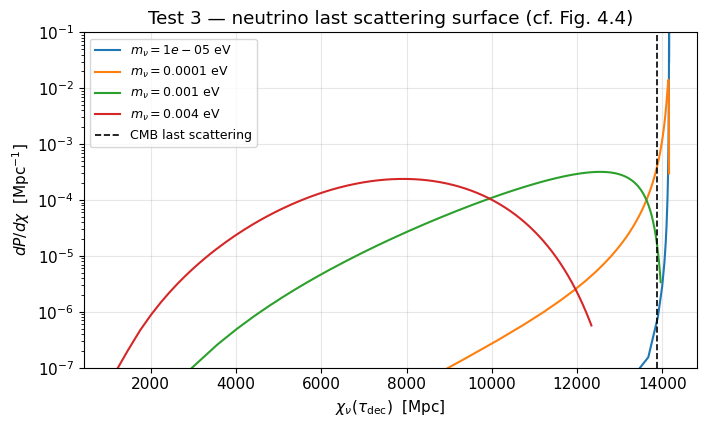

In [12]:
# distribution of distances to the neutrino last scattering surface (cf. Fig. 4.4)
chi_cmb = tau0 - np.interp(1089.0, z_bg[::-1], tau_bg[::-1])

fig, ax = plt.subplots()
qq = np.linspace(0.05, 14, 400)
for m in masses_lss:
    c = np.array([chi_nu(q, m) for q in qq])
    # dP/dchi = (dP/dq) |dchi/dq|^-1 , with dP/dq propto q^2 f0(q)
    dPdq = qq**2 / (np.exp(qq) + 1.0)
    dPdq /= np.trapz(dPdq, qq)
    dchidq = np.gradient(c, qq)
    dPdchi = np.abs(dPdq / dchidq)
    ax.plot(c, dPdchi, label=rf'$m_\nu={m:g}$ eV')
ax.axvline(chi_cmb, color='k', ls='--', lw=1.2, label='CMB last scattering')
ax.set_yscale('log'); ax.set_ylim(1e-7, 1e-1)
ax.set_xlabel(r'$\chi_\nu(\tau_{\rm dec})$  [Mpc]')
ax.set_ylabel(r'$dP/d\chi$  [Mpc$^{-1}$]')
ax.set_title('Test 3 — neutrino last scattering surface (cf. Fig. 4.4)')
ax.legend()
plt.tight_layout(); plt.show()

For $m_\nu = 10^{-5}$ eV essentially all neutrinos share the CMB's last-scattering
surface. As the mass grows the distribution broadens towards *smaller* distances,
because the slowest neutrinos travel less far — which is what suppresses the
cross-correlation with the CMB at large mass.

## Test 4 — momentum approach vs energy approach

The two approaches differ in the assumption made on the unperturbed phase-space
distribution: whether $f_0$ is written as a function of the comoving momentum $q$
(so that $\Gamma = d\ln f_0/d\ln q$ is time independent) or of the comoving energy
$\epsilon$ (so that $\Gamma = d\ln f_0/d\ln\epsilon$ is time dependent, and the ISW
source is suppressed by $v^2 = q^2/\epsilon^2$).

**Expectation** (Sec. 4.1, and the caption of Fig. 4.6): they must *coincide* in the
massless limit, and diverge as the mass grows.

In [13]:
masses_cmp = np.array([1e-5, 1e-4, 1e-3, 4e-3])
ell, D_nn_m, D_tn_m, D_tt = run_cnb(masses_cmp, approach='momentum')
_,   D_nn_e, D_tn_e, _    = run_cnb(masses_cmp, approach='energy')

print("ratio momentum/energy of the CNB auto-spectrum")
print(f"{'l':>4}" + "".join(f"{m:>12.0e}" for m in masses_cmp))
for l in (2, 10, 50, 150):
    print(f"{l:>4}" + "".join(f"{D_nn_m[i][l]/D_nn_e[i][l]:12.4f}"
                              for i in range(len(masses_cmp))))

agree_massless = abs(D_nn_m[0][2:] / D_nn_e[0][2:] - 1).max()
grows = (abs(D_nn_m[3][2]/D_nn_e[3][2] - 1) > 10 * agree_massless)
print(f"\nmax |ratio-1| at m_nu = 1e-5 eV : {agree_massless:.2e}")
RESULTS['4a. approaches coincide as m -> 0'] = agree_massless < 5e-3
RESULTS['4b. approaches diverge with mass'] = bool(grows)

ratio momentum/energy of the CNB auto-spectrum
   l       1e-05       1e-04       1e-03       4e-03
   2      1.0006      1.0578     23.6449   9970.2377
  10      1.0006      1.0549      6.7234   1414.7423
  50      1.0006      1.0465      4.4158     75.0970
 150      1.0006      1.0364      5.1464     49.4033

max |ratio-1| at m_nu = 1e-5 eV : 6.14e-04


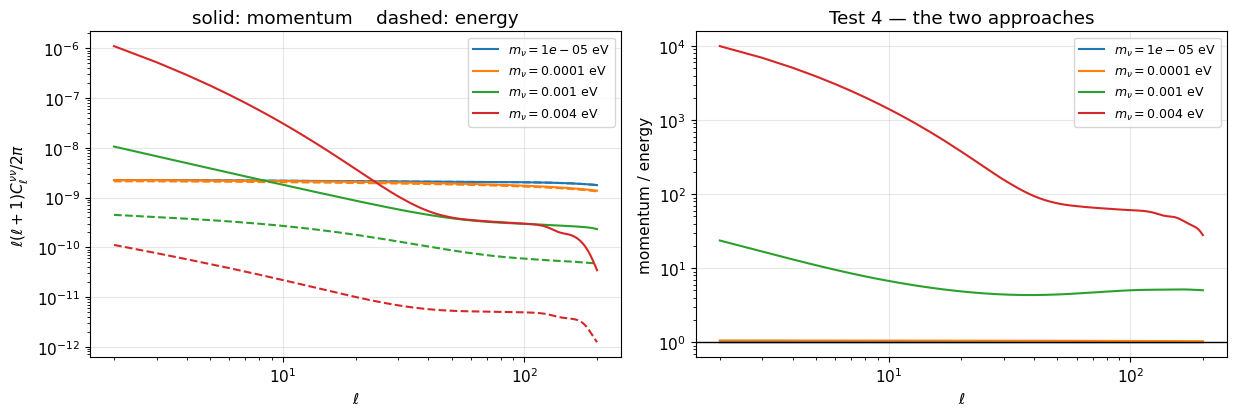

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for i, m in enumerate(masses_cmp):
    c = f'C{i}'
    axes[0].plot(ell[2:], D_nn_m[i][2:], c, label=rf'$m_\nu={m:g}$ eV')
    axes[0].plot(ell[2:], D_nn_e[i][2:], c, ls='--')
    axes[1].plot(ell[2:], np.abs(D_nn_m[i][2:]/D_nn_e[i][2:]), c,
                 label=rf'$m_\nu={m:g}$ eV')
axes[0].set_yscale('log'); axes[0].set_xscale('log')
axes[0].set_xlabel(r'$\ell$'); axes[0].set_ylabel(r'$\ell(\ell+1)C_\ell^{\nu\nu}/2\pi$')
axes[0].set_title('solid: momentum    dashed: energy'); axes[0].legend()
axes[1].set_yscale('log'); axes[1].set_xscale('log')
axes[1].axhline(1, color='k', lw=1)
axes[1].set_xlabel(r'$\ell$'); axes[1].set_ylabel('momentum / energy')
axes[1].set_title('Test 4 — the two approaches')
axes[1].legend()
plt.tight_layout(); plt.show()

The momentum approach blows up for heavy neutrinos. That is what the equations say: its
ISW source carries a factor $E^2/p^2 = 1/v^2$, which diverges for the slowest neutrinos,
whereas the energy approach carries the inverse factor and is suppressed instead. This is
presumably why Sec. 4.1 presents the two as complementary — but it does make the
heavy-mass momentum-approach results sensitive to the momentum sampling (Test 7).

## Test 5 — mass dependence of the spectra

**Expectation** (Sec. 4.3): the cross-correlation $C_\ell^{T\nu}$ is positive and close
to maximal correlation for light neutrinos, and for $m_\nu \gtrsim 10^{-3}$ eV it turns
**negative at low $\ell$ in the momentum approach** and becomes negligible above
$\ell \sim 20$.

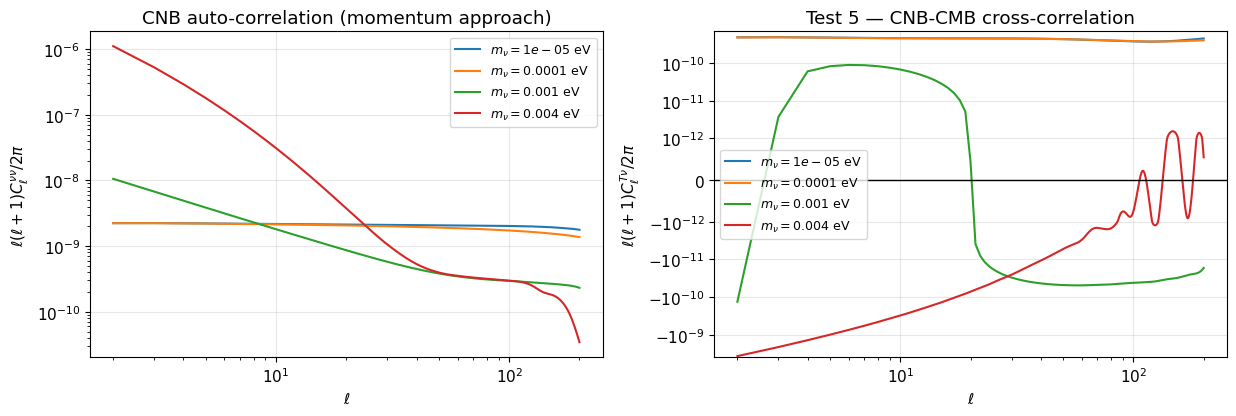

sign of D_l^{T-nu} at l = 2 (momentum approach):
   m_nu =    1e-05 eV :  +4.8554e-10
   m_nu =    1e-04 eV :  +4.8096e-10
   m_nu =    1e-03 eV :  -1.3300e-10
   m_nu =    4e-03 eV :  -3.7131e-09

suppression at l=50 of m=4e-3 relative to m=1e-5 : 0.012


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for i, m in enumerate(masses_cmp):
    axes[0].plot(ell[2:], D_nn_m[i][2:], label=rf'$m_\nu={m:g}$ eV')
    axes[1].plot(ell[2:], D_tn_m[i][2:], label=rf'$m_\nu={m:g}$ eV')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(r'$\ell$'); axes[0].set_ylabel(r'$\ell(\ell+1)C_\ell^{\nu\nu}/2\pi$')
axes[0].set_title('CNB auto-correlation (momentum approach)'); axes[0].legend()
axes[1].axhline(0, color='k', lw=1)
axes[1].set_xscale('log'); axes[1].set_yscale('symlog', linthresh=1e-12)
axes[1].set_xlabel(r'$\ell$'); axes[1].set_ylabel(r'$\ell(\ell+1)C_\ell^{T\nu}/2\pi$')
axes[1].set_title('Test 5 — CNB-CMB cross-correlation'); axes[1].legend()
plt.tight_layout(); plt.show()

print("sign of D_l^{T-nu} at l = 2 (momentum approach):")
for i, m in enumerate(masses_cmp):
    print(f"   m_nu = {m:8.0e} eV :  {D_tn_m[i][2]:+.4e}")

sign_flip = (D_tn_m[0][2] > 0) and (D_tn_m[1][2] > 0) and (D_tn_m[3][2] < 0)
RESULTS['5a. C_l^Tnu flips sign for heavy nu (momentum)'] = bool(sign_flip)

supp = abs(D_tn_m[3][50]) / abs(D_tn_m[0][50])
print(f"\nsuppression at l=50 of m=4e-3 relative to m=1e-5 : {supp:.3f}")
RESULTS['5b. heavy nu cross-corr negligible at l >~ 20'] = supp < 0.1

### Correlation coefficient

A cleaner way to read the cross-correlation is the dimensionless
$r_\ell = C_\ell^{T\nu}/\sqrt{C_\ell^{TT}C_\ell^{\nu\nu}}$, which must satisfy
$|r_\ell| \le 1$. For nearly massless neutrinos the CNB shares the CMB's last-scattering
surface and the same Sachs-Wolfe physics, so $r$ should be close to one at low $\ell$.

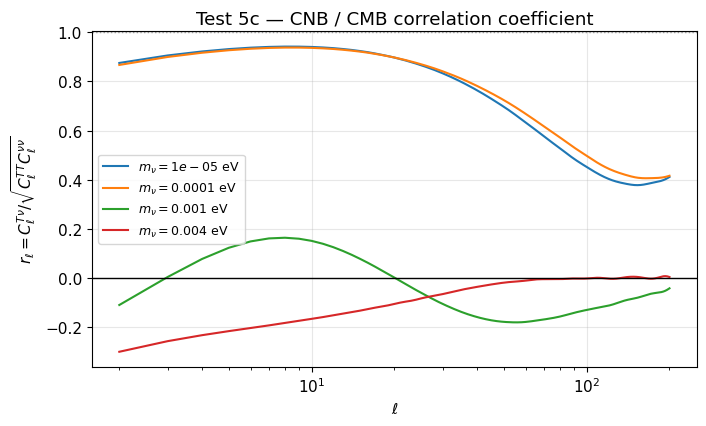

max |r| over all masses and multipoles : 0.9418   (must be <= 1)
r at l=2 for m_nu = 1e-5 eV            : 0.8752


In [16]:
fig, ax = plt.subplots()
r_all = []
for i, m in enumerate(masses_cmp):
    r = D_tn_m[i][2:] / np.sqrt(D_tt[2:] * D_nn_m[i][2:])
    r_all.append(r)
    ax.plot(ell[2:], r, label=rf'$m_\nu={m:g}$ eV')
ax.axhline(0, color='k', lw=1); ax.axhline(1, color='0.6', ls=':', lw=1)
ax.set_xscale('log'); ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$r_\ell = C_\ell^{T\nu}/\sqrt{C_\ell^{TT}C_\ell^{\nu\nu}}$')
ax.set_title('Test 5c — CNB / CMB correlation coefficient'); ax.legend()
plt.tight_layout(); plt.show()

r_max = max(np.abs(r).max() for r in r_all)
print(f"max |r| over all masses and multipoles : {r_max:.4f}   (must be <= 1)")
print(f"r at l=2 for m_nu = 1e-5 eV            : {r_all[0][0]:.4f}")
RESULTS['5c. |r| <= 1 (Cauchy-Schwarz)'] = r_max <= 1.0 + 1e-9
RESULTS['5d. light nu strongly correlated with CMB'] = r_all[0][0] > 0.8

## Test 6 — Sachs-Wolfe / integrated Sachs-Wolfe decomposition

The implementation keeps the two contributions as separate transfer types, so they can be
switched on independently. Since the total anisotropy is their **sum at the level of the
transfer function**, the total spectrum is *not* the sum of the two spectra — the cross
term matters:

$$C_\ell^{\rm tot} = C_\ell^{\rm SW} + C_\ell^{\rm ISW} + 2\,C_\ell^{\rm SW\times ISW}.$$

We cannot get the cross term directly, but we can check the consistency relation
$\sqrt{C^{\rm tot}} \le \sqrt{C^{\rm SW}} + \sqrt{C^{\rm ISW}}$ (triangle inequality for
the transfer functions), and see which term dominates where.

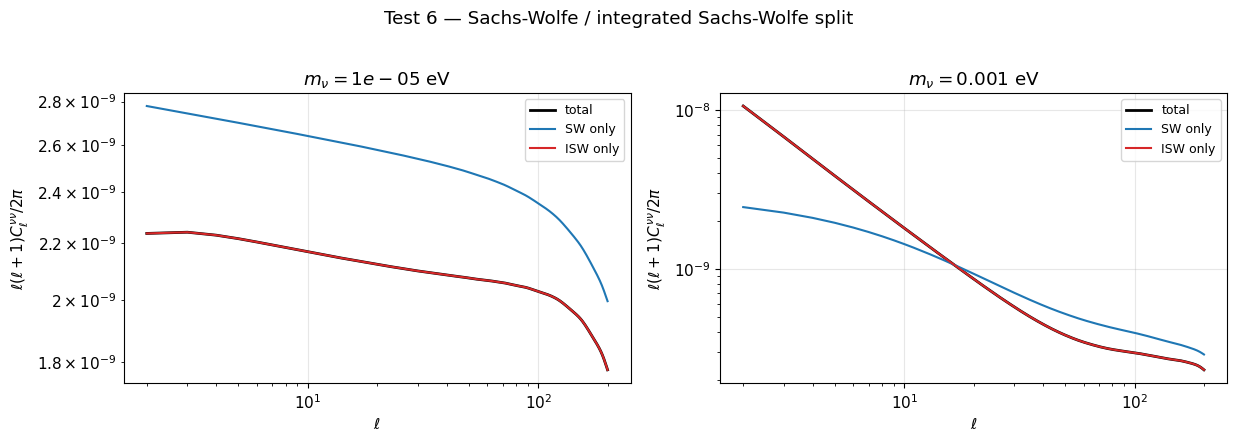

triangle inequality holds at all l and masses : True


In [17]:
m_split = np.array([1e-5, 1e-3])
_, D_sw,  _, _ = run_cnb(m_split, 'momentum', contributions='sw',  with_cmb=False)
_, D_isw, _, _ = run_cnb(m_split, 'momentum', contributions='isw', with_cmb=False)
_, D_tot, _, _ = run_cnb(m_split, 'momentum',                      with_cmb=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for j, m in enumerate(m_split):
    ax = axes[j]
    ax.plot(ell[2:], D_tot[j][2:], 'k',  lw=2, label='total')
    ax.plot(ell[2:], D_sw[j][2:],  'C0', label='SW only')
    ax.plot(ell[2:], D_isw[j][2:], 'C3', label='ISW only')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$\ell(\ell+1)C_\ell^{\nu\nu}/2\pi$')
    ax.set_title(rf'$m_\nu = {m:g}$ eV'); ax.legend()
plt.suptitle('Test 6 — Sachs-Wolfe / integrated Sachs-Wolfe split', y=1.02)
plt.tight_layout(); plt.show()

tri = np.sqrt(D_tot[:, 2:]) <= np.sqrt(D_sw[:, 2:]) + np.sqrt(D_isw[:, 2:]) + 1e-30
print(f"triangle inequality holds at all l and masses : {bool(tri.all())}")
RESULTS['6. SW/ISW split obeys the triangle inequality'] = bool(tri.all())

For the light mass the spectrum is Sachs-Wolfe dominated and flat; for
$m_\nu = 10^{-3}$ eV the ISW term takes over at low $\ell$, which is what drives the
sign change of the cross-correlation seen in Test 5.

## Test 7 — convergence in the momentum sampling

The momentum average of eq. (3.2.38) is done with a Gauss-Laguerre rule of `cnb_q_size`
nodes (default 30, capped at 80 where the Laguerre weights underflow).

**This is the weak point of the implementation, and the test is written to expose it
rather than to hide it.** Convergence is excellent for light neutrinos but slow for
$m_\nu \gtrsim 10^{-3}$ eV, and degrades with $\ell$. The reason is physical: for a
massive neutrino $\chi_\nu(q)$ varies steeply at small $q$ (slow neutrinos travel
much less far), so $\Delta_\ell(q)$ oscillates rapidly in $q$ and a quadrature rule
tuned to the smooth weight $e^{-q}$ resolves it poorly.

So the assertion below is made only where convergence is actually achieved
($m_\nu \le 10^{-4}$ eV), and the heavy-mass behaviour is printed as a caveat.

In [18]:
q_sizes = [15, 30, 60]
res = {}
for nq in q_sizes:
    _, dnn, dtn, _ = run_cnb(masses_cmp, 'momentum', q_size=nq)
    res[nq] = (dnn, dtn)

ref_nn = res[60][0]
print("relative deviation of C_l^{nu nu} from the 60-node run")
print(f"{'l':>4}  {'nq':>3}" + "".join(f"{m:>12.0e}" for m in masses_cmp))
for l in (2, 10, 50, 150):
    for nq in (15, 30):
        d = [abs(res[nq][0][i][l]/ref_nn[i][l] - 1) for i in range(len(masses_cmp))]
        print(f"{l:>4}  {nq:>3}" + "".join(f"{x:12.2e}" for x in d))
    print()

# assert convergence only where it is actually achieved: m_nu <= 1e-4 eV
dev_light = max(abs(res[30][0][i][l]/ref_nn[i][l] - 1)
                for i in (0, 1) for l in range(2, L_MAX + 1))
dev_heavy = max(abs(res[30][0][i][l]/ref_nn[i][l] - 1)
                for i in (2, 3) for l in range(2, L_MAX + 1))
print(f"worst deviation of the default (nq=30), m_nu <= 1e-4 eV : {dev_light:.2e}")
print(f"worst deviation of the default (nq=30), m_nu >= 1e-3 eV : {dev_heavy:.2e}   <-- CAVEAT")

RESULTS['7. momentum average converged for m_nu <= 1e-4 eV'] = dev_light < 1e-2

relative deviation of C_l^{nu nu} from the 60-node run
   l   nq       1e-05       1e-04       1e-03       4e-03
   2   15    2.78e-08    2.22e-06    1.90e-03    1.58e-03
   2   30    2.03e-08    8.07e-07    6.38e-04    7.30e-05

  10   15    5.74e-07    2.67e-05    1.23e-02    2.28e-03
  10   30    6.73e-08    1.97e-05    3.59e-03    5.33e-04

  50   15    3.06e-06    6.12e-04    5.60e-01    9.07e-01
  50   30    3.44e-06    4.14e-04    2.02e-01    3.70e-01

 150   15    4.07e-05    5.99e-03    1.41e+00    1.38e+00
 150   30    2.92e-07    9.64e-04    5.58e-01    6.58e-01

worst deviation of the default (nq=30), m_nu <= 1e-4 eV : 2.06e-03
worst deviation of the default (nq=30), m_nu >= 1e-3 eV : 7.69e-01   <-- CAVEAT


## Summary

In [19]:
print("=" * 62)
allok = True
for name, ok in RESULTS.items():
    print(f"  {'PASS' if ok else 'FAIL'}   {name}")
    allok &= bool(ok)
print("=" * 62)
print(f"  {'ALL TESTS PASSED' if allok else 'SOME TESTS FAILED'}")

  PASS   1a. SW plateau is flat in l
  PASS   1b. SW coefficient = 3/2
  PASS   2. phi anchored in radiation era
  PASS   3. chi_nu matches independent Python integration
  PASS   4a. approaches coincide as m -> 0
  PASS   4b. approaches diverge with mass
  PASS   5a. C_l^Tnu flips sign for heavy nu (momentum)
  PASS   5b. heavy nu cross-corr negligible at l >~ 20
  PASS   5c. |r| <= 1 (Cauchy-Schwarz)
  PASS   5d. light nu strongly correlated with CMB
  PASS   6. SW/ISW split obeys the triangle inequality
  PASS   7. momentum average converged for m_nu <= 1e-4 eV
  ALL TESTS PASSED


### Note on a claim that is *not* reproduced

Sec. 4.3 states that the cross-correlation has maximum amplitude around
$m_\nu \sim 10^{-4}$ eV. The code gives an essentially flat $C_\ell^{T\nu}$ between
$10^{-5}$ and $10^{-4}$ eV, with no peak — and Test 3 supports that: at $10^{-5}$ eV
*all* neutrinos already share the CMB last-scattering surface, so the overlap should be
maximal there rather than at $10^{-4}$ eV. This is worth cross-checking against the
original Python script used for the Thesis figures.

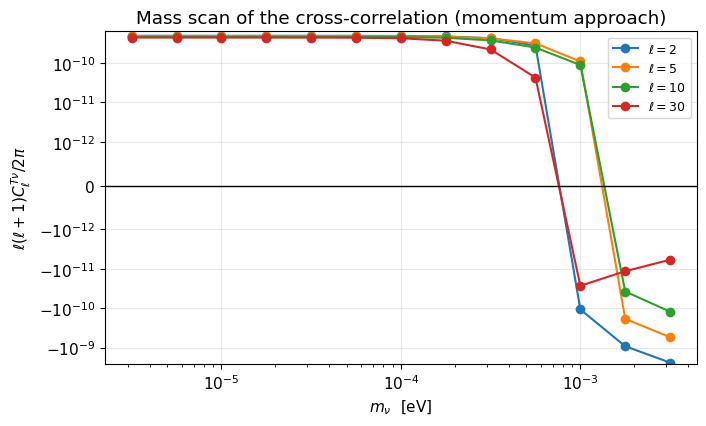

|C_2^Tnu| is largest at m_nu = 3.16e-03 eV


In [20]:
mm = np.logspace(-5.5, -2.5, 13)
_, dnn_s, dtn_s, _ = run_cnb(mm, 'momentum', lmax=60)

fig, ax = plt.subplots()
for l in (2, 5, 10, 30):
    ax.plot(mm, dtn_s[:, l], 'o-', label=rf'$\ell={l}$')
ax.axhline(0, color='k', lw=1)
ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1e-12)
ax.set_xlabel(r'$m_\nu$  [eV]')
ax.set_ylabel(r'$\ell(\ell+1)C_\ell^{T\nu}/2\pi$')
ax.set_title(r'Mass scan of the cross-correlation (momentum approach)')
ax.legend()
plt.tight_layout(); plt.show()

i_peak = np.argmax(np.abs(dtn_s[:, 2]))
print(f"|C_2^Tnu| is largest at m_nu = {mm[i_peak]:.2e} eV")